# Part 5 — Pseudoinverse

Exercises 5.1–5.3 from the sheet: the three roads to `A^+`, left vs right inverse, and the projection picture of Example 2.2.

## Setup

`A^+` is computed from the full SVD in `pinv_svd`, and `projection_axes` draws the column-space plane with `t`, `t_hat` and the residual.

In [1]:
import io

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import HTML, Image as IPyImage, display

np.set_printoptions(precision=4, suppress=True)

TOL = 1e-12


def numerical_rank(s):
    """Rank from the singular values, with a relative threshold."""
    return int(np.sum(s > TOL * max(1.0, float(s[0]))))


def pinv_svd(A):
    """A^+ = V Sigma^+ U^T, inverting only the r nonzero singular values."""
    U, s, Vt = np.linalg.svd(A, full_matrices=True)
    r = numerical_rank(s)
    S = np.zeros((A.shape[1], A.shape[0]))
    S[:r, :r] = np.diag(1.0 / s[:r])
    return Vt.T @ S @ U.T


def plane_grid(A, lo=-1.0, hi=1.0, n=9):
    """Grid over the two column coefficients, for drawing col(A)."""
    a = np.linspace(lo, hi, n)
    C1, C2 = np.meshgrid(a, a)
    pts = A[:, :2] @ np.vstack([C1.ravel(), C2.ravel()])
    return (pts[0].reshape(C1.shape), pts[1].reshape(C1.shape),
            pts[2].reshape(C1.shape))


def projection_axes(ax, A, t, P, lim=4.0):
    """Plane col(A), the vector t, t_hat = Pt and the residual e = t - t_hat."""
    th = P @ t
    e = t - th
    ax.plot_surface(*plane_grid(A), color="0.82", alpha=0.45,
                    linewidth=0, shade=False)
    ax.quiver(0.0, 0.0, 0.0, *t, color="black", lw=2.0, arrow_length_ratio=0.07)
    ax.plot(*np.vstack([np.zeros(3), th]).T, color="royalblue", lw=2.6)
    ax.quiver(*th, *e, color="crimson", lw=2.2, arrow_length_ratio=0.07)
    ax.text(*(1.05 * t), "t", color="black")
    ax.text(*(th + np.array([0.0, 0.0, 0.12])), "t\u0302", color="royalblue")
    ax.text(*(th + 0.55 * e), "e", color="crimson")
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim),
           xlabel="$y_1$", ylabel="$y_2$", zlabel="$y_3$")
    ax.view_init(elev=22, azim=34)
    return th, e


print("numpy", np.__version__, "| ipywidgets", widgets.__version__)

numpy 2.5.4 | ipywidgets 8.1.9


## 5.1 — Three roads to A†

### Task

Take the tall full-column-rank matrix of Example 1.14/2.2, its wide transpose, and the rank-deficient square matrix whose third row is row 1 + row 2. Compute

$$A^\dagger_{\text{left}}=(A^\top A)^{-1}A^\top,\qquad A^\dagger_{\text{right}}=A^\top(AA^\top)^{-1},\qquad A^\dagger=V\Sigma^\dagger U^\top,$$

with \(\Sigma^\dagger=\mathrm{diag}(1/\sigma_1,\dots,1/\sigma_r,0,\dots,0)\in\mathbb{R}^{n\times m}\), and compare each result with `np.linalg.pinv`.

In [2]:
# --- Task: the three matrices and the four roads to A^+ ------------------
A_tall = np.array([[2.0, 1.0], [1.0, 3.0], [0.0, 1.0]])       # Example 1.14 / 2.2
A_wide = A_tall.T
A_sq = np.array([[2.0, 1.0, 0.0],
                 [1.0, 3.0, 1.0],
                 [3.0, 4.0, 1.0]])                            # row 3 = row 1 + row 2
MATS = {"tall 3x2": A_tall, "wide 2x3": A_wide, "square 3x3": A_sq}


def left_road(A):
    """(A^T A)^-1 A^T, defined only for full column rank."""
    if np.linalg.matrix_rank(A) < A.shape[1]:
        return None
    return np.linalg.inv(A.T @ A) @ A.T


def right_road(A):
    """A^T (A A^T)^-1, defined only for full row rank."""
    if np.linalg.matrix_rank(A) < A.shape[0]:
        return None
    return A.T @ np.linalg.inv(A @ A.T)


print("%-12s %-7s %-5s %-8s %s" % ("matrix", "shape", "rank", "road", "max|M - pinv|"))
for name, A in MATS.items():
    s = np.linalg.svd(A, compute_uv=False)
    ref = np.linalg.pinv(A)
    for road, M in (("left", left_road(A)), ("right", right_road(A)),
                    ("SVD", pinv_svd(A))):
        err = "not defined" if M is None else "%.2e" % np.abs(M - ref).max()
        print("%-12s %-7s %-5d %-8s %s"
              % (name, str(A.shape), numerical_rank(s), road, err))

print("\nA^+ from the SVD road")
for name, A in MATS.items():
    print("%-12s" % name); print(pinv_svd(A))

matrix       shape   rank  road     max|M - pinv|
tall 3x2     (3, 2)  2     left     2.22e-16
tall 3x2     (3, 2)  2     right    not defined
tall 3x2     (3, 2)  2     SVD      2.78e-17
wide 2x3     (2, 3)  2     left     not defined
wide 2x3     (2, 3)  2     right    2.22e-16
wide 2x3     (2, 3)  2     SVD      2.78e-17
square 3x3   (3, 3)  2     left     not defined
square 3x3   (3, 3)  2     right    not defined
square 3x3   (3, 3)  2     SVD      5.55e-17

A^+ from the SVD road
tall 3x2    
[[ 0.5667 -0.1333 -0.1667]
 [-0.1667  0.3333  0.1667]]
wide 2x3    
[[ 0.5667 -0.1667]
 [-0.1333  0.3333]
 [-0.1667  0.1667]]
square 3x3  
[[ 0.4333 -0.3     0.1333]
 [-0.2     0.2667  0.0667]
 [-0.1667  0.1667  0.    ]]


In [3]:
# --- Task: the four Penrose identities ------------------------------------
print("--- checks ---")
checks = {}
for name, A in MATS.items():
    Ap = pinv_svd(A)
    checks[name + ": A A+ A = A"] = np.allclose(A @ Ap @ A, A)
    checks[name + ": A+ A A+ = A+"] = np.allclose(Ap @ A @ Ap, Ap)
    checks[name + ": (A A+)^T = A A+"] = np.allclose((A @ Ap).T, A @ Ap)
    checks[name + ": (A+ A)^T = A+ A"] = np.allclose((Ap @ A).T, Ap @ A)
    checks[name + ": SVD road = pinv"] = np.allclose(Ap, np.linalg.pinv(A))
for name, ok in checks.items():
    print("%-38s %s" % (name, ok))

--- checks ---
tall 3x2: A A+ A = A                   True
tall 3x2: A+ A A+ = A+                 True
tall 3x2: (A A+)^T = A A+              True
tall 3x2: (A+ A)^T = A+ A              True
tall 3x2: SVD road = pinv              True
wide 2x3: A A+ A = A                   True
wide 2x3: A+ A A+ = A+                 True
wide 2x3: (A A+)^T = A A+              True
wide 2x3: (A+ A)^T = A+ A              True
wide 2x3: SVD road = pinv              True
square 3x3: A A+ A = A                 True
square 3x3: A+ A A+ = A+               True
square 3x3: (A A+)^T = A A+            True
square 3x3: (A+ A)^T = A+ A            True
square 3x3: SVD road = pinv            True


### Explain

The left road inverts \(A^\top A\), which is possible exactly when \(A\) has full column rank: then \(N(A)=\{0\}\) and \(A^\top A\) is nonsingular. It works for the tall matrix, and fails for the wide one (\(n>m\) forces rank \(<n\)) and for the rank-deficient square one. The right road inverts \(AA^\top\), possible exactly when \(A\) has full row rank; it works for the wide matrix and fails for the tall and rank-deficient ones. On the square rank-deficient matrix both products are singular, so neither one-sided formula exists.

The SVD road always works: \(U\) and \(V\) are orthogonal, and \(\Sigma^\dagger\) is the \(n\times m\) matrix that inverts the \(r\) nonzero singular values and leaves the zeros at zero. No inverse of \(A^\top A\) or \(AA^\top\) is taken, so rank deficiency is handled by construction. The one-sided roads are special cases of the same expression: \((A^\top A)^{-1}A^\top=V\Sigma^{-1}U^\top\) when \(r=n\), and \(A^\top(AA^\top)^{-1}=V\Sigma^{-1}U^\top\) when \(r=m\).

## 5.2 — Left vs right inverse

### Task

For the same three matrices, compute \(A^\dagger A\) and \(AA^\dagger\). For the product that is not the identity, check \(P^2=P=P^\top\) and identify the subspace it projects onto.

In [4]:
# --- Task: A^+ A and A A^+ ------------------------------------------------
def product_kind(P, size):
    """Identity of that size, or the rank of the orthogonal projector."""
    if np.allclose(P, np.eye(size)):
        return "I_%d" % size
    return "projector, rank %d" % np.linalg.matrix_rank(P)


print("%-12s %-7s %-22s %s" % ("matrix", "shape", "A+ A (n x n)", "A A+ (m x m)"))
for name, A in MATS.items():
    Ap = pinv_svd(A)
    print("%-12s %-7s %-22s %s"
          % (name, str(A.shape), product_kind(Ap @ A, A.shape[1]),
             product_kind(A @ Ap, A.shape[0])))

print("\n--- checks ---")
checks = {}
for name, A in MATS.items():
    Ap = pinv_svd(A)
    Pc, Pr = A @ Ap, Ap @ A
    checks[name + ": P_col^2 = P_col"] = np.allclose(Pc @ Pc, Pc)
    checks[name + ": P_col^T = P_col"] = np.allclose(Pc.T, Pc)
    checks[name + ": P_row^2 = P_row"] = np.allclose(Pr @ Pr, Pr)
    checks[name + ": P_row^T = P_row"] = np.allclose(Pr.T, Pr)
    checks[name + ": P_col A = A"] = np.allclose(Pc @ A, A)
    checks[name + ": A P_row = A"] = np.allclose(A @ Pr, A)
    checks[name + ": rank P_col = rank A"] = (np.linalg.matrix_rank(Pc)
                                              == np.linalg.matrix_rank(A))
    checks[name + ": rank P_row = rank A"] = (np.linalg.matrix_rank(Pr)
                                              == np.linalg.matrix_rank(A))
for name, ok in checks.items():
    print("%-38s %s" % (name, ok))

matrix       shape   A+ A (n x n)           A A+ (m x m)
tall 3x2     (3, 2)  I_2                    projector, rank 2
wide 2x3     (2, 3)  projector, rank 2      I_2
square 3x3   (3, 3)  projector, rank 2      projector, rank 2

--- checks ---
tall 3x2: P_col^2 = P_col              True
tall 3x2: P_col^T = P_col              True
tall 3x2: P_row^2 = P_row              True
tall 3x2: P_row^T = P_row              True
tall 3x2: P_col A = A                  True
tall 3x2: A P_row = A                  True
tall 3x2: rank P_col = rank A          True
tall 3x2: rank P_row = rank A          True
wide 2x3: P_col^2 = P_col              True
wide 2x3: P_col^T = P_col              True
wide 2x3: P_row^2 = P_row              True
wide 2x3: P_row^T = P_row              True
wide 2x3: P_col A = A                  True
wide 2x3: A P_row = A                  True
wide 2x3: rank P_col = rank A          True
wide 2x3: rank P_row = rank A          True
square 3x3: P_col^2 = P_col            True
square 

### Explain

For the tall full-column-rank matrix \(A^\dagger A=I_2\), so \(A^\dagger\) is a left inverse. \(AA^\dagger\) cannot be \(I_3\): it has rank \(r=2<3\). It is the orthogonal projector onto the column space, the plane spanned by the two columns of \(A\).

For the wide full-row-rank matrix \(AA^\dagger=I_2\), so \(A^\dagger\) is a right inverse. \(A^\dagger A\) has rank 2 in \(\mathbb{R}^3\) and projects onto the row space, which is the column space of \(A^\top\).

For the rank-deficient square matrix neither product is the identity, since both have rank \(r=2<3\). \(AA^\dagger\) still projects onto the column space and \(A^\dagger A\) onto the row space. In every case \(\operatorname{rank}(AA^\dagger)=\operatorname{rank}(A^\dagger A)=r\), so a product can equal an identity only when the corresponding dimension equals \(r\); otherwise it is a rank-\(r\) orthogonal projector onto \(\operatorname{col}(A)\) (for \(AA^\dagger\)) or \(\operatorname{row}(A)\) (for \(A^\dagger A\)).

## 5.3 — Projection in pictures

### Task

Take \(A\) from Example 2.2 (3 × 2). Plot its column space as a plane in 3-D, a vector \(t\), its projection \(\hat t\) and the residual \(e\):

$$\hat t=Pt=A(A^\top A)^{-1}A^\top t,\qquad e=t-\hat t.$$

P =
[[ 0.9667  0.0667 -0.1667]
 [ 0.0667  0.8667  0.3333]
 [-0.1667  0.3333  0.1667]]
t = [2. 1. 2.]   t_hat = [1.6667 1.6667 0.3333]   e = [ 0.3333 -0.6667  1.6667]
||t|| = 3.0000   ||t_hat|| = 2.3805   ||e|| = 1.8257
A^T e = [-0. -0.]
--- checks ---
P matches Example 2.2        True
P^2 = P                      True
P^T = P                      True
P A = A                      True
t_hat = P t                  True
t = t_hat + e                True
A^T e = 0                    True
e = (I - P) t                True


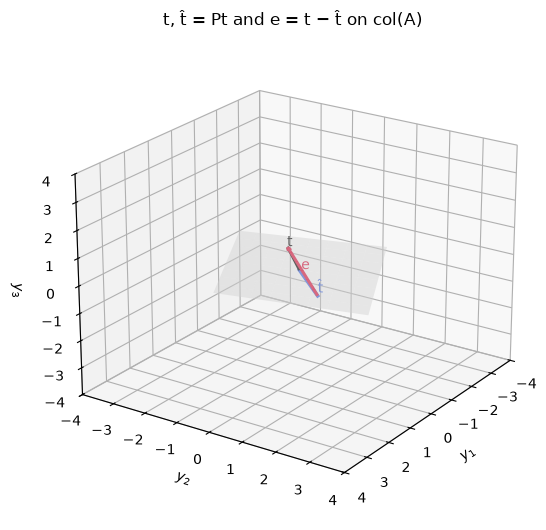

In [5]:
# --- Task: Example 2.2, P, t, t_hat, e and the 3-D picture -----------------
A = A_tall
P = A @ np.linalg.inv(A.T @ A) @ A.T
t0 = np.array([2.0, 1.0, 2.0])
th0 = P @ t0
e0 = t0 - th0

print("P ="); print(P)
print("t =", t0, "  t_hat =", th0, "  e =", e0)
print("||t|| = %.4f   ||t_hat|| = %.4f   ||e|| = %.4f"
      % (np.linalg.norm(t0), np.linalg.norm(th0), np.linalg.norm(e0)))
print("A^T e =", A.T @ e0)

fig = plt.figure(figsize=(6.2, 5.4))
ax = fig.add_subplot(projection="3d")
projection_axes(ax, A, t0, P)
ax.set_title("t, t\u0302 = Pt and e = t \u2212 t\u0302 on col(A)")
fig.tight_layout()
plt.show()

print("--- checks ---")
checks = {
    "P matches Example 2.2": np.allclose(
        P, np.array([[29.0, 2.0, -5.0],
                     [2.0, 26.0, 10.0],
                     [-5.0, 10.0, 5.0]]) / 30.0),
    "P^2 = P": np.allclose(P @ P, P),
    "P^T = P": np.allclose(P.T, P),
    "P A = A": np.allclose(P @ A, A),
    "t_hat = P t": np.allclose(th0, P @ t0),
    "t = t_hat + e": np.allclose(t0, th0 + e0),
    "A^T e = 0": np.allclose(A.T @ e0, 0.0),
    "e = (I - P) t": np.allclose(e0, (np.eye(3) - P) @ t0),
}
for name, ok in checks.items():
    print("%-28s %s" % (name, ok))

### Explore

Move \(t\) over a sphere of radius 2.5 with the two sliders; the read-out follows the picture.

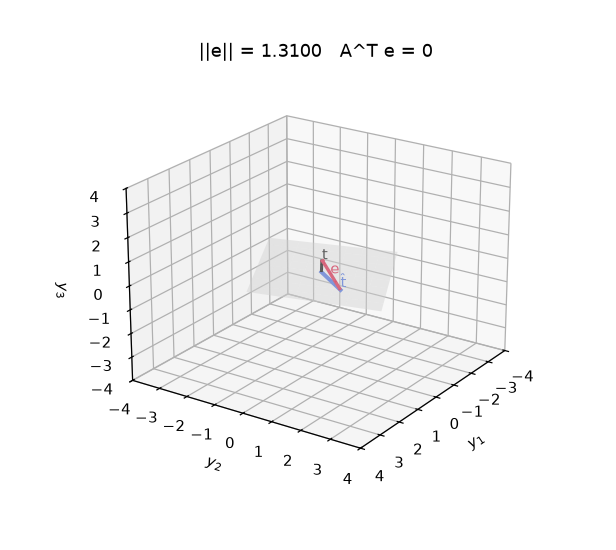

In [6]:
# --- Explore: move t with two sliders --------------------------------------
# Read-out and picture are shown once and replaced in place on every move,
# so the output does not blink while a slider moves.
RADIUS = 2.5
theta = widgets.FloatSlider(value=0.6, min=0.0, max=2.0 * np.pi, step=0.05,
                            description="\u03b8", continuous_update=True,
                            layout=widgets.Layout(width="380px"))
phi = widgets.FloatSlider(value=0.9, min=-0.5 * np.pi, max=0.5 * np.pi, step=0.05,
                          description="\u03c6", continuous_update=True,
                          layout=widgets.Layout(width="380px"))
_handles = {}


def show(key, obj):
    """Display obj once, then update that same output in place."""
    if key in _handles:
        _handles[key].update(obj)
    else:
        _handles[key] = display(obj, display_id="5.3 " + key)


def refresh(*_):
    t = RADIUS * np.array([np.sin(phi.value) * np.cos(theta.value),
                           np.sin(phi.value) * np.sin(theta.value),
                           np.cos(phi.value)])
    th = P @ t
    e = t - th
    show("readout", HTML(
        "<pre>t     = (%+.3f, %+.3f, %+.3f)\n"
        "t_hat = (%+.3f, %+.3f, %+.3f)\n"
        "e     = (%+.3f, %+.3f, %+.3f)\n"
        "||t|| = %.4f   ||t_hat|| = %.4f   ||e|| = %.4f\n"
        "A^T e = (%+.1e, %+.1e)   t_hat . e = %+.1e</pre>"
        % (*t, *th, *e, np.linalg.norm(t), np.linalg.norm(th),
           np.linalg.norm(e), *(A.T @ e), th @ e)))
    fig = plt.figure(figsize=(5.6, 5.0))
    ax = fig.add_subplot(projection="3d")
    projection_axes(ax, A, t, P)
    ax.set_title("||e|| = %.4f   A^T e = 0" % np.linalg.norm(e))
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110)
    plt.close(fig)
    show("picture", IPyImage(data=buf.getvalue(), format="png"))


display(widgets.VBox([widgets.HTML("<b>Direction of t</b>"), theta, phi]))
theta.observe(refresh, names="value")
phi.observe(refresh, names="value")
refresh()

### Explain

The residual is \(e=t-\hat t=(I-P)t\). With \(P=A(A^\top A)^{-1}A^\top\),

$$A^\top e=A^\top t-A^\top A(A^\top A)^{-1}A^\top t=0,$$

so \(e\) is orthogonal to every column of \(A\), hence to the whole column-space plane, and \(\|e\|\) is the distance from \(t\) to that plane.

The set of vectors orthogonal to \(\operatorname{col}(A)\) is the left null space \(N(A^\top)\). Therefore \(e\in N(A^\top)\), while \(\hat t\in\operatorname{col}(A)\): the picture is the orthogonal decomposition

$$\mathbb{R}^3=\operatorname{col}(A)\oplus N(A^\top).$$

The residual lives in the left null space, the projection in the column space. This also explains why \(P^2=P=P^\top\), and why \(\hat t=Pt\) is the closest point of the plane to \(t\): any other point of the plane differs from \(\hat t\) by a vector of the plane, which is orthogonal to \(e\) and therefore can only increase the distance.